# Video Game Completion Time Prediction — Midterm
**Direction 42 | Regression | Target: Main-story completion time (hours)**

**Research question:** How accurately can we predict the main-story completion duration of a video game from **structured metadata** (genres, developer-catalog proxy, price, release year, tags)?

**Hypothesis (to test):** At least one structured regression model has lower held-out MAE than predicting the same median duration for every game. **Not a pre-established result.**

> This notebook requires **real source data**. No made-up rows or scores are used. Run `src/collect_igdb.py` (official IGDB requires Twitch API credentials) or `src/collect_mirror.py` (third-party published compilation) and then `src/prepare.py`. The source used is recorded in the manifest and must be disclosed. All NLP of descriptions is reserved for Final; the Endterm adds clustering and advanced models.

Course guide: *Course Project: Guide* (Weeks 4–10), pp. 1–2. The separate Midterm rubric was not included.

## 1. Data card and provenance

A row is a single video game (after deduplication), with metadata available before predicting duration. The main output is a positive number of **hours**, not a review class.

| Column | Type | Meaning / used in Midterm? |
|---|---|---|
| `game_id`, `title`, `steam_appid` | ID / text | Provenance and matching, **excluded from models** |
| `main_story_hours` | Float, > 0 | **Target**: HowLongToBeat main hours or IGDB `hastily / 3600` |
| `primary_genre`, `genres_text` | Category / multi-category | Main genre and other genres, **yes** |
| `primary_developer` | Category | Developer name for training-fold frequency tier, **yes** |
| `price_usd`, `price_missing` | Nullable float / binary | USD list price and missingness flag, **yes** |
| `release_year` | Nullable float | Release calendar year, **yes** |
| `tags_text` | Multi-category | Game tags, **yes** (NOT natural-language description) |
| `description` | Text | Description retained for **Final NLP only** |
| `description_word_count`, `source_url` | Int / URL | Quality and provenance, **excluded from models** |

**Important:** IGDB `hastily` means minimal time to main credits, while IGDB `normally` mixes in side content. HLTB `main` is a similar but separate community metric. Do not silently combine the targets. The no-credential mirror is a *third-party compilation* of underlying sources rather than a direct IGDB/HLTB crawl. Source access/terms require student verification.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

HERE = Path.cwd().resolve()
ROOT = HERE if (HERE / 'src' / 'train.py').exists() else HERE.parent
assert (ROOT / 'src' / 'train.py').exists(), 'Run the notebook from the project root or notebooks/ directory.'
sys.path.insert(0, str(ROOT / 'src'))
from common import RAW, CLEAN, OUT, SEED
from train import INPUT, run as train_models

print('Project:', ROOT)
print('Seed:', SEED)

Matplotlib is building the font cache; this may take a moment.


Project: D:\AITU\mla\midterm\video_games_midterm
Seed: 42


In [2]:
manifest_path = RAW / 'collection_manifest.json'
quality_path = CLEAN / 'cleaning_report.json'
file_path = CLEAN / 'games_clean.csv'

if not file_path.exists():
    raise FileNotFoundError('Real cleaned data missing. Read README.md: first run src/collect_igdb.py or src/collect_mirror.py, then src/prepare.py.')

source = json.loads(manifest_path.read_text(encoding='utf-8'))
quality = json.loads(quality_path.read_text(encoding='utf-8'))
print('Collection method:', source.get('collection_method'))
print('Collection date (UTC):', source.get('collected_at_utc'))
print('Raw before cleaning:', quality['raw_rows'], '| Clean after:', quality['cleaned_rows'])
print('Raw snapshot SHA256:', source.get('snapshot_sha256', source.get('raw_subset_sha256')))
print('Source page:', source.get('source_page', source.get('main_source')))
assert quality['cleaned_rows'] >= 3000, 'The project goal is at least 3,000 cleaned real games.'
df = pd.read_csv(file_path, dtype={'game_id': str})
assert len(df) == quality['cleaned_rows']
display(df[['title','main_story_hours','release_year','price_usd','primary_genre','primary_developer']].head(8))

Collection method: IGDB official API + optional Steam store appdetails
Collection date (UTC): 2026-10-08T08:56:44+00:00
Raw before cleaning: 5273 | Clean after: 5229
Raw snapshot SHA256: 5fbad5100572060e625d0037e705f29c0d212b8f644a0a1b4b19aa25f0631277
Source page: https://api.igdb.com/v4/game_time_to_beats


,title,main_story_hours,release_year,price_usd,primary_genre,primary_developer
0,Thief II: The Metal Age,28.0,2000.0,NaN,Adventure,Looking Glass Studios
1,Morkredd,4.0,2020.0,NaN,Indie,Hyper Games
2,"Batman: Arkham Origins - Cold, Cold Heart",2.0,2014.0,NaN,Adventure,Rocksteady Studios
3,Ancestors: The Humankind Odyssey,19.0,2019.0,NaN,Adventure,Panache Digital Games
4,Temtem,100.0,2022.0,NaN,Adventure,CremaGames
5,The Matrix: Path of Neo,9.0,2005.0,NaN,Hack and slash/Beat 'em up,Shiny Entertainment
6,Watch Dogs: Legion,18.0,2020.0,NaN,Adventure,Ubisoft Toronto
7,BioShock Infinite: Burial at Sea - Episode 1,2.5,2013.0,NaN,Shooter,Irrational Games


### Collection summary and rights

The collector stores its UTC date and actual request/download source in the manifest. The fallback uses a published [Game Gauntlets Steam Game Database](https://github.com/leinstay/steamdb), licensed GPL-3.0 as a *compilation*, with descriptions belonging to other rights holders. The strict original-source option uses [IGDB official API](https://api-docs.igdb.com/) and optional Steam Store API. The student's previously stated robots.txt/terms check must be reviewed against current rules; do **not** imply we bypassed IGDB authentication.

## 2. Data cleaning and quality control

We remove invalid or missing targets (without ever estimating them), empty descriptions, obviously unusable records, duplicates by game ID and normalized title/year. Raw price is in cents and is converted to USD. Metadata missingness is retained; imputation and scaling happen **inside** the training pipeline, not before splitting.

In [3]:
display(pd.DataFrame([quality]).T.rename(columns={0:'Value'}))
print('Duplicates by ID:', df.game_id.duplicated().sum())
print('Missing values (%)')
display((100 * df[['release_year','price_usd','primary_genre','tags_text','main_story_hours']].isna().mean()).round(1).to_frame('Missing %'))
assert df['main_story_hours'].notna().all() and (df['main_story_hours'] > 0).all()
assert len(df) >= 3000

,Value
prepared_at_utc,2026-10-08T09:00:08+00:00
raw_path,D:\AITU\mla\midterm\video_games_midterm\data\r...
raw_rows,5273
excluded_target,28
excluded_text,5
excluded_title,1
excluded_any,34
duplicate_or_near_duplicate_removed,10
cleaned_rows,5229
columns,"[game_id, steam_appid, title, main_story_hours..."


Duplicates by ID: 0
Missing values (%)


,Missing %
release_year,0.0
price_usd,100.0
primary_genre,0.0
tags_text,100.0
main_story_hours,0.0


## 3. Exploratory analysis

Characterize the target's right tail, group representation and possible predictors *without looking at the held-out outcomes to choose models*. Plots are exploratory; they do not establish that features predict completion time.

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
cap = df.main_story_hours.quantile(.98)
axes[0].hist(df.main_story_hours.clip(upper=cap), bins=35)
axes[0].set(title='Main-story hours (capped at 98th percentile)', xlabel='Hours', ylabel='Games')
df.primary_genre.value_counts().head(10).sort_values().plot(kind='barh', ax=axes[1])
axes[1].set(title='Top primary genres', xlabel='Games', ylabel='Genre')
plt.tight_layout(); plt.show()
print('Target percentiles (hours):')
display(df.main_story_hours.quantile([.05,.25,.50,.75,.90,.95,.99]).rename('Hours').to_frame())

Target percentiles (hours):


C:\Users\User\AppData\Local\Temp\ipykernel_21148\658196066.py:7: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.tight_layout(); plt.show()


,Hours
0.05,1.0
0.25,2.0
0.50,5.0
0.75,12.0
0.90,25.0
0.95,40.0
0.99,100.0


In [5]:
print('Price missing: {:.1%}'.format(df.price_usd.isna().mean()))
print('Release year missing: {:.1%}'.format(df.release_year.isna().mean()))
print('Tags missing/empty: {:.1%}'.format(df.tags_text.isna().mean() + df.tags_text.fillna('').eq('').mean() - (df.tags_text.isna() & df.tags_text.fillna('').eq('')).mean()))
display(df.groupby('primary_genre').main_story_hours.agg(['count','median','mean']).query('count >= 20').sort_values('count', ascending=False).head(12).round(2))

Price missing: 100.0%
Release year missing: 0.0%
Tags missing/empty: 100.0%


,count,median,mean
primary_genre,,,
Adventure,3083,6.00,13.37
Indie,444,3.00,10.85
Role-playing (RPG),298,15.00,21.25
Arcade,265,1.50,10.39
Shooter,251,5.33,16.05
Fighting,149,3.00,8.82
Hack and slash/Beat 'em up,94,6.00,11.56
Platform,89,3.02,6.08
Simulator,84,4.50,16.12


## 4. Train/test protocol and engineered features

- **80% train, 20% test**, random seed **42**. IDs are permanently stored in `data/clean/fixed_split.csv` and must be reused at Endterm/Final.
- Three-fold shuffled CV, performed **only on training data**, chooses the model using **MAE**.
- Preprocessing on training folds: numeric median-imputation + scaling, categorical imputation/one-hot encoding, multi-hot genre/tag encoding, developer frequency tier derived **within each fold**.
- Developer tier is merely the number of games by the same developer in the collected sample, **not verified AAA/indie tier**.
- Descriptions, title, game IDs, source URLs and target-derived metrics are **excluded** from predictors.
- Positive right-tailed targets use `log1p` during training; all reported errors are computed in actual hours after `expm1` inverse.

Models: DummyRegressor (training median), Linear Regression, Ridge Regression, Decision Tree Regression and KNN Regression. Ensemble learning, clustering, neural networks and NLP are postponed to later stages.

In [6]:
print('Predictor columns:', INPUT)
print('Target:', 'main_story_hours')
print('Note: text description and title NOT in predictor columns.')
assert 'description' not in INPUT and 'title' not in INPUT and 'main_story_hours' not in INPUT

Predictor columns: ['release_year', 'price_usd', 'price_missing', 'primary_genre', 'primary_developer', 'genres_text', 'tags_text']
Target: main_story_hours
Note: text description and title NOT in predictor columns.


## 5. Fit and compare supervised models

This section executes the pipeline using **only real CSV rows**. Expect 3-fold CV on the training data and one held-out evaluation for every candidate. The winner is selected by cross-validation MAE, **not** by checking which has the best test score. The script creates numeric result CSVs, a fitted joblib model and charts.

In [7]:
comparison = train_models(file_path, reset_split=False, skip_cv=False, min_rows=3000)
display(comparison.sort_values('train_cv_MAE_hours').style.format({
    'train_cv_MAE_hours': '{:.2f}', 'MAE_hours': '{:.2f}', 'RMSE_hours': '{:.2f}',
    'R2': '{:.3f}', 'MedAE_hours':'{:.2f}', 'MAPE_percent':'{:.1f}', 'sMAPE_percent':'{:.1f}'
}))

Fitting: Dummy (median)
  Test MAE: 13.013 | R2: -0.041
Fitting: Linear Regression
  Test MAE: 11.83 | R2: -0.005
Fitting: Ridge Regression
  Test MAE: 11.816 | R2: -0.012
Fitting: Decision Tree
  Test MAE: 11.814 | R2: 0.006
Fitting: K-Nearest Neighbors
  Test MAE: 11.907 | R2: -0.006
Chosen model based on CV: Ridge Regression
Saved measured results and figures to D:\AITU\mla\midterm\video_games_midterm\outputs


,model,train_cv_MAE_hours,MAE_hours,RMSE_hours,R2,MedAE_hours,MAPE_percent,sMAPE_percent
2,Ridge Regression,10.07,11.82,51.43,-0.012,3.20,122.0,74.9
1,Linear Regression,10.12,11.83,51.26,-0.005,3.29,121.7,74.8
3,Decision Tree,10.19,11.81,50.96,0.006,3.26,125.5,74.7
4,K-Nearest Neighbors,10.40,11.91,51.27,-0.006,3.25,119.5,72.4
0,Dummy (median),11.07,13.01,52.17,-0.041,4.00,148.1,87.6


### Metrics

**MAE (hours):** average absolute hour error; primary comparison metric. **RMSE (hours):** disproportionately penalizes large mistakes. **R²:** variance explained relative to predicting a constant mean; can be negative. **Median AE:** robust typical mistake. **MAPE/sMAPE (%):** relative error; MAPE is vulnerable when actual time is very short. These are **measured** only after execution, never inserted by hand.

In [8]:
run_info = json.loads((OUT / 'experiment_manifest.json').read_text(encoding='utf-8'))
winner = run_info['best_cv_model']
score = comparison.set_index('model')
print('Best model by training CV:', winner)
print('Best model test MAE (hours):', round(score.loc[winner,'MAE_hours'],2))
print('Dummy test MAE (hours):', round(score.loc['Dummy (median)','MAE_hours'],2))
difference = score.loc['Dummy (median)','MAE_hours'] - score.loc[winner,'MAE_hours']
print('MAE improvement over baseline (hours):', round(difference,2))
print('Does chosen model beat dummy baseline on TEST?', bool(difference > 0))

Best model by training CV: Ridge Regression
Best model test MAE (hours): 11.82
Dummy test MAE (hours): 13.01
MAE improvement over baseline (hours): 1.2
Does chosen model beat dummy baseline on TEST? True


## 6. Held-out error analysis

Inspect error relative to game length, and identify games with the largest deviations. Avoid asserting specific reasons for outliers without reading their metadata.

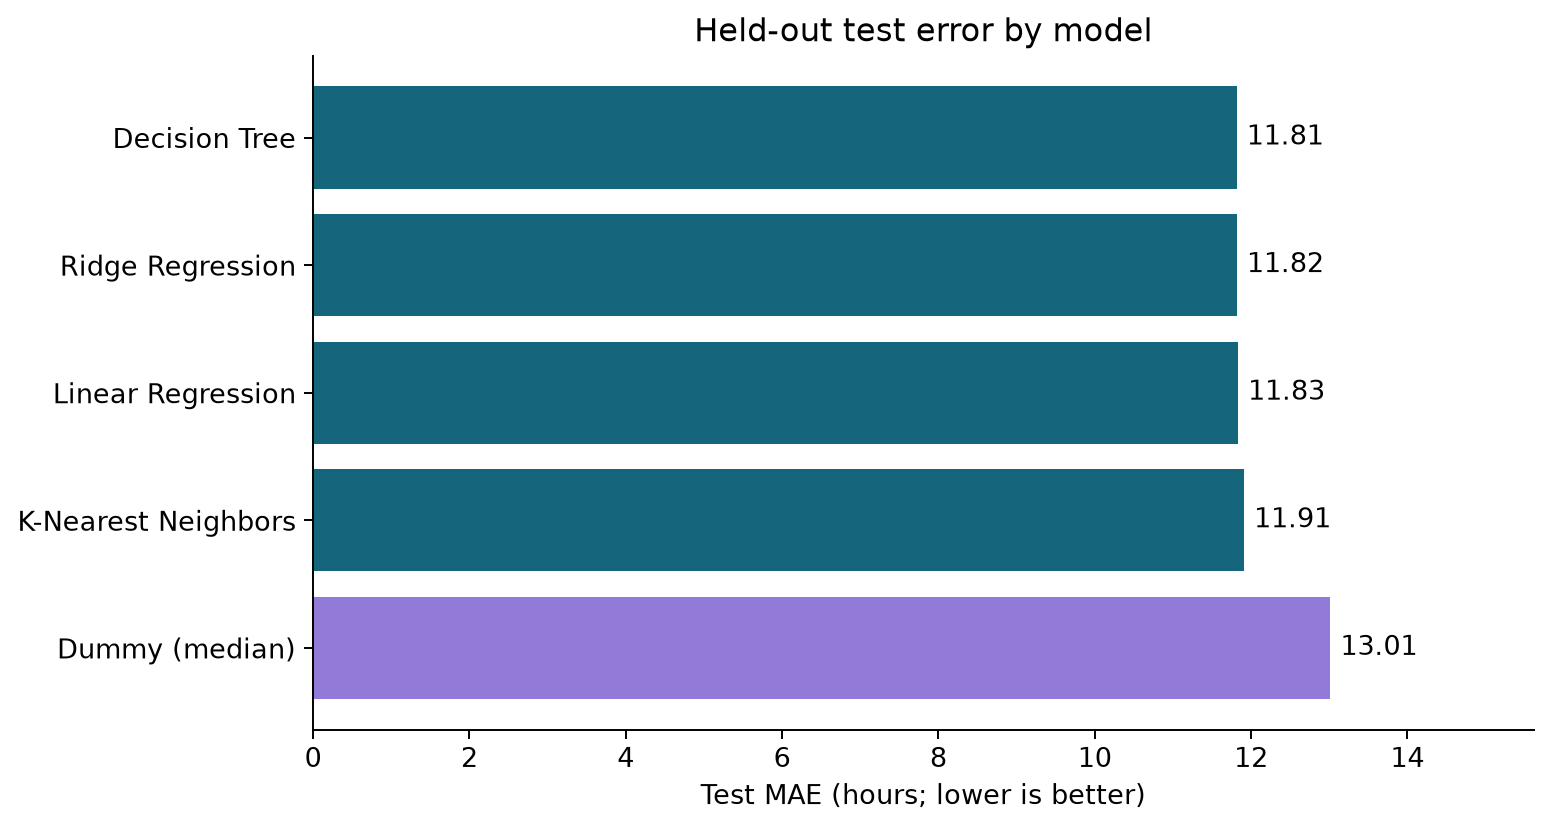

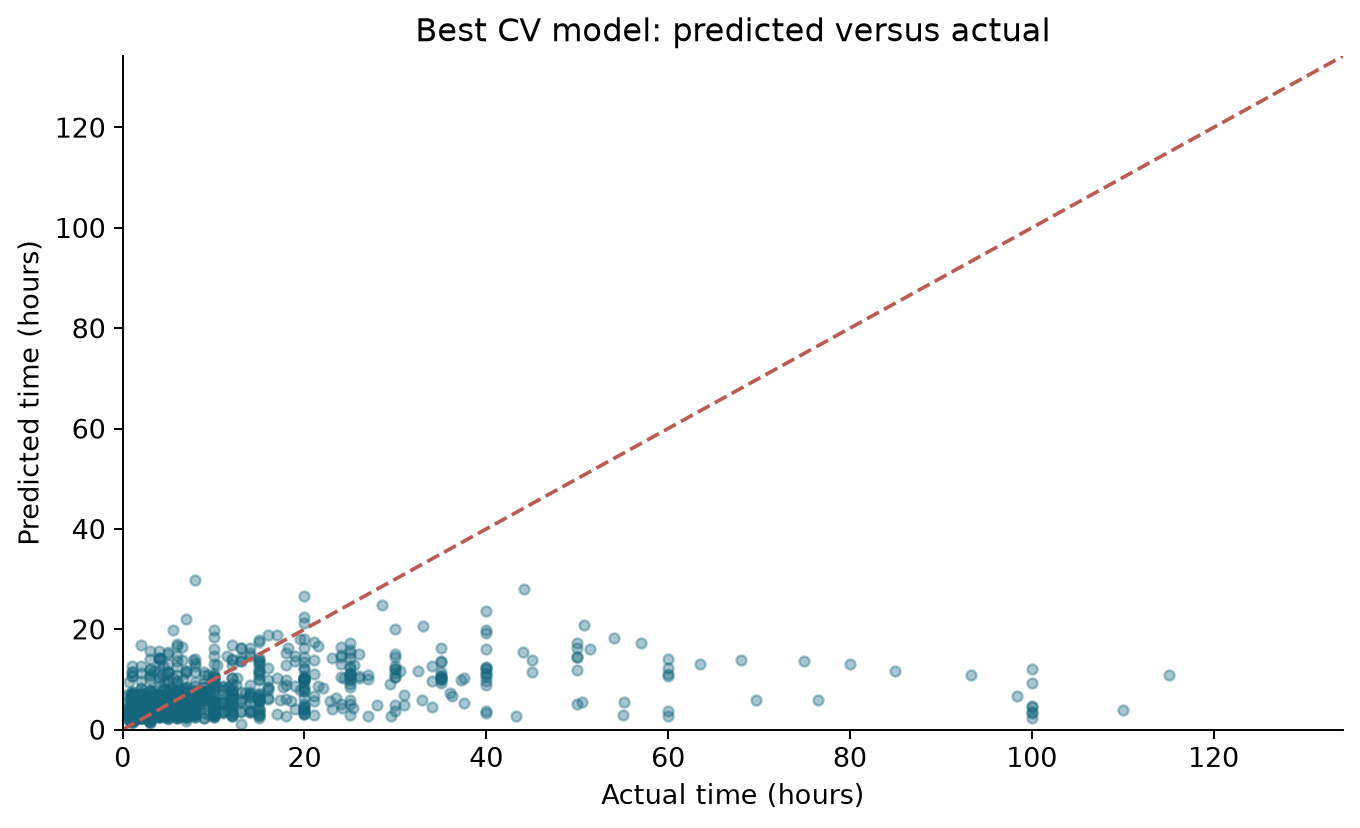

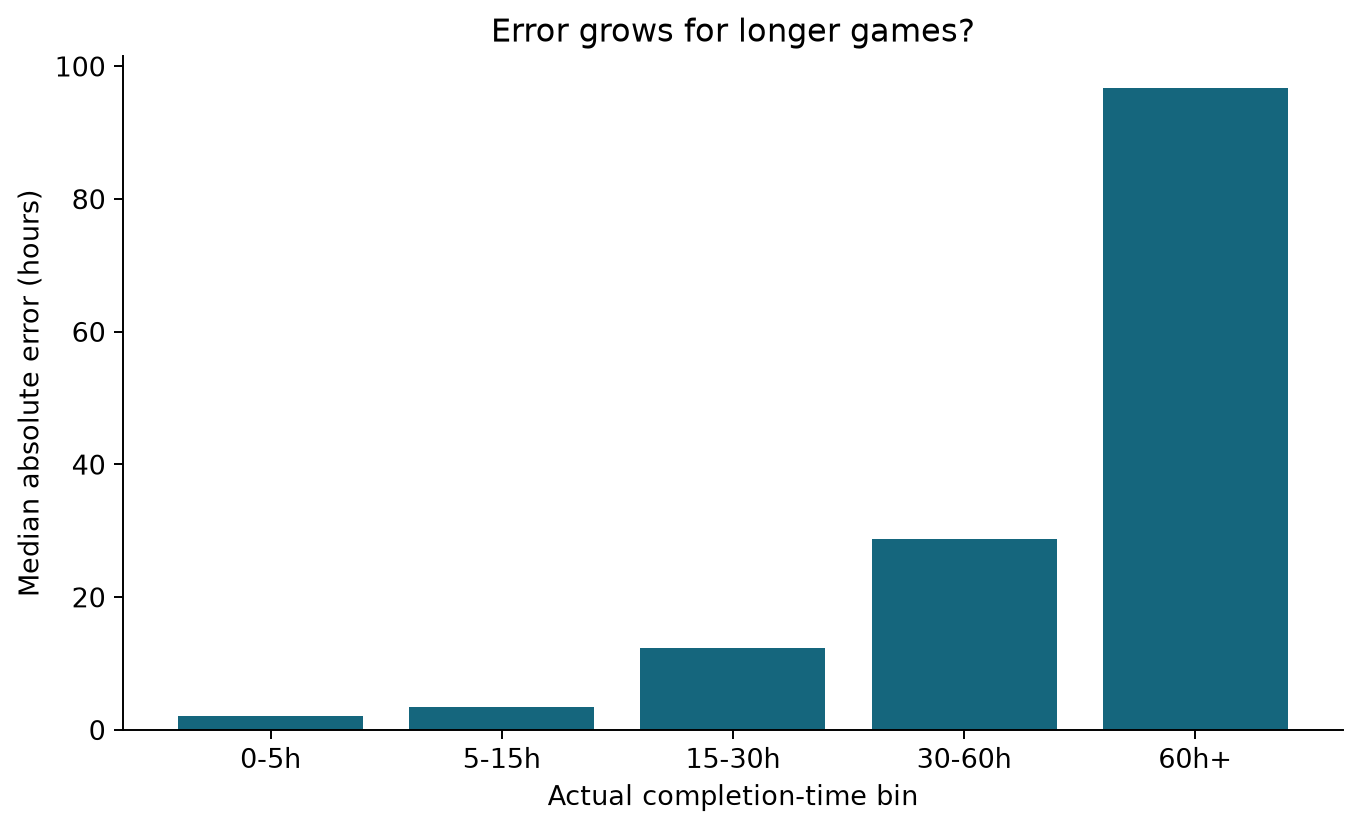

Largest absolute test errors:


,title,primary_genre,actual_hours,predicted_hours,absolute_error
240,Gorilla Tag,Arcade,997.50,1.40,996.10
197,Grand Theft Auto Online,Adventure,513.00,7.81,505.19
958,Rainbow Six Siege,Shooter,500.00,6.45,493.55
977,Old School RuneScape,Adventure,486.50,12.53,473.97
785,HDOS,Adventure,486.00,12.75,473.25
107,Genshin Impact,Adventure,468.49,12.63,455.86
722,R.E.P.O.,Indie,350.00,3.92,346.08
69,Dragon Ball Z: Kakarot,Adventure,348.33,12.29,336.04
900,Brawl Stars,MOBA,342.00,11.59,330.41
384,Riders of Icarus,Adventure,168.00,12.14,155.86


In [9]:
from IPython.display import Image, display
for f in ('model_mae.png','prediction_vs_actual.png','error_by_time.png'):
    display(Image(filename=str(OUT / 'figures' / f), width=640))
predictions = pd.read_csv(OUT / 'test_predictions.csv')
print('Largest absolute test errors:')
display(predictions.nlargest(12, 'absolute_error')[['title','primary_genre','actual_hours','predicted_hours','absolute_error']].round(2))

In [10]:
genre_errors = pd.read_csv(OUT / 'error_by_genre.csv')
print('Genres represented by at least 10 test games:')
display(genre_errors.head(15).round(2))
# Are errors in hours larger for games with very long stories?
predictions['duration_bucket'] = pd.cut(predictions.actual_hours,
    [0,5,15,30,60,1000], labels=['0-5h','5-15h','15-30h','30-60h','60h+'], include_lowest=True)
display(predictions.groupby('duration_bucket', observed=True).absolute_error.agg(['size','median','mean']).round(2))

Genres represented by at least 10 test games:


,primary_genre,count,mean,median
0,Arcade,45,27.37,1.52
1,Shooter,52,13.40,2.84
2,Indie,70,13.17,2.67
3,Adventure,638,11.33,3.35
4,Hack and slash/Beat 'em up,29,10.74,5.41
5,Role-playing (RPG),52,10.54,8.62
6,Unknown,21,9.02,2.83
7,Racing,13,8.24,3.07
8,Simulator,20,8.23,5.05
9,Platform,23,7.45,2.88


,size,median,mean
duration_bucket,,,
0-5h,505,2.03,2.65
5-15h,328,3.49,4.23
15-30h,121,12.39,12.26
30-60h,63,28.81,31.08
60h+,29,96.70,213.58


## 7. Interpretation and limitations

Use the measured table and residual charts to answer: **How large is the typical hour error? Did the selected model beat the median dummy? Which kinds of games show worse errors?**

**Limitations:** This is a non-random catalog of games with time-to-beat records, so especially unpopular or multiplayer-only games may not be represented. Main-story duration is a community estimate. Missing tags/prices can weaken some predictors; region/time influence Steam prices. A random game-level holdout is not the same as prospective accuracy for brand-new releases. A single primary genre and the developer-count proxy simplify reality. The direct IGDB and indirect HLTB targets have different definitions and must not be mixed.

In [11]:
baseline = score.loc['Dummy (median)']
chosen = score.loc[winner]
conclusion = (
    f"On a fixed 20% held-out test set ({run_info['test_rows']} games), the model selected "
    f"by training-fold CV was {winner}. It achieved MAE {chosen['MAE_hours']:.2f} hours, "
    f"RMSE {chosen['RMSE_hours']:.2f} hours and R² {chosen['R2']:.3f}. "
    f"The median dummy achieved MAE {baseline['MAE_hours']:.2f} hours. "
    + ('The chosen model improved MAE by ' + f'{difference:.2f} hours.' if difference > 0
       else 'The chosen model did not improve test MAE over the dummy baseline.')
)
display(Markdown('**Evidence-based midterm conclusion:** ' + conclusion))

**Evidence-based midterm conclusion:** On a fixed 20% held-out test set (1046 games), the model selected by training-fold CV was Ridge Regression. It achieved MAE 11.82 hours, RMSE 51.43 hours and R² -0.012. The median dummy achieved MAE 13.01 hours. The chosen model improved MAE by 1.20 hours.

## 8. Endterm and Final plan

**Endterm:** tune Random Forest, gradient boosting and other ensembles while preserving the split; K-means clustering of structured game profiles and interpretation of segments; train a neural network for regression.

**Final:** experiment with game description **TF-IDF**. On the **same game IDs** and with comparable models, evaluate (a) structured only, (b) description only, (c) combined. Estimate uncertainty of paired MAE differences and check whether any improvement is robust. Create a local app that estimates hours from a new game's metadata and/or description.

**Contribution & AI-use statement — complete before Moodle:**

- **Partner 1:** [name + actual tasks: collection, ethics, raw snapshot, data card]
- **Partner 2:** [name + actual tasks: cleaning, features, baselines, modeling, plots]
- **Both:** [actual joint tasks]
- **AI tools:** ChatGPT-assisted scaffolding of scripts, documentation, slides and notebook; numeric scores/dataset must be genuinely reproduced by the team's run. Adapt disclosure to your actual usage.

**Guide submission:** both partners submit the same notebook, collection code, raw + clean data/link and 7–9 slides; defense is 7–10 minutes + 3–5 minutes Q&A. Notebook outputs and slides must agree.

In [12]:
# After obtaining real results, rebuild the editable presentation with actual numbers:
from build_slides import generate as regenerate_slides
slides_path = regenerate_slides()
print('Defense PowerPoint:', slides_path)

Saved D:\AITU\mla\midterm\video_games_midterm\slides\Video_Game_Midterm_Defense.pptx | 9 slides | measured results: True
Defense PowerPoint: D:\AITU\mla\midterm\video_games_midterm\slides\Video_Game_Midterm_Defense.pptx
